Libraries imported successfully!

Dataset created successfully!
Dataset Shape: (20, 2)

First 5 Records:
                                                text  category
0  patient has high blood sugar and frequent urin...  Diabetes
1  patient has increased glucose level and excess...  Diabetes
2  patient diagnosed with diabetes and insulin re...  Diabetes
3  blood sugar levels are elevated and patient fe...  Diabetes
4  patient has diabetic symptoms and increased gl...  Diabetes

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      20 non-null     object
 1   category  20 non-null     object
dtypes: object(2)
memory usage: 452.0+ bytes

Class Distribution:
category
Diabetes         5
Heart Disease    5
Cancer           5
Other            5
Name: count, dtype: int64


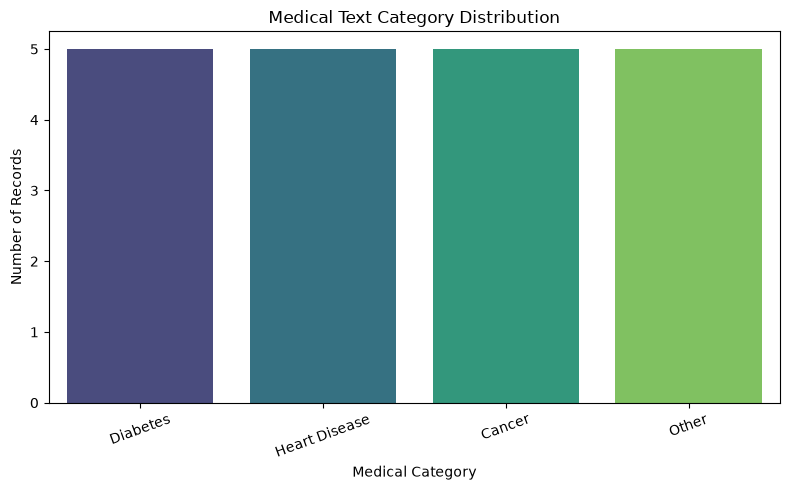


Original and Cleaned Text:
                                                text  \
0  patient has high blood sugar and frequent urin...   
1  patient has increased glucose level and excess...   
2  patient diagnosed with diabetes and insulin re...   
3  blood sugar levels are elevated and patient fe...   
4  patient has diabetic symptoms and increased gl...   
5     patient has chest pain and shortness of breath   
6  patient has high blood pressure and chest disc...   
7  patient reports irregular heartbeat and chest ...   
8  patient has cardiovascular symptoms and diffic...   
9        patient has hypertension and heart problems   

                                          clean_text  
0  patient has high blood sugar and frequent urin...  
1  patient has increased glucose level and excess...  
2  patient diagnosed with diabetes and insulin re...  
3  blood sugar levels are elevated and patient fe...  
4  patient has diabetic symptoms and increased gl...  
5     patient has chest p

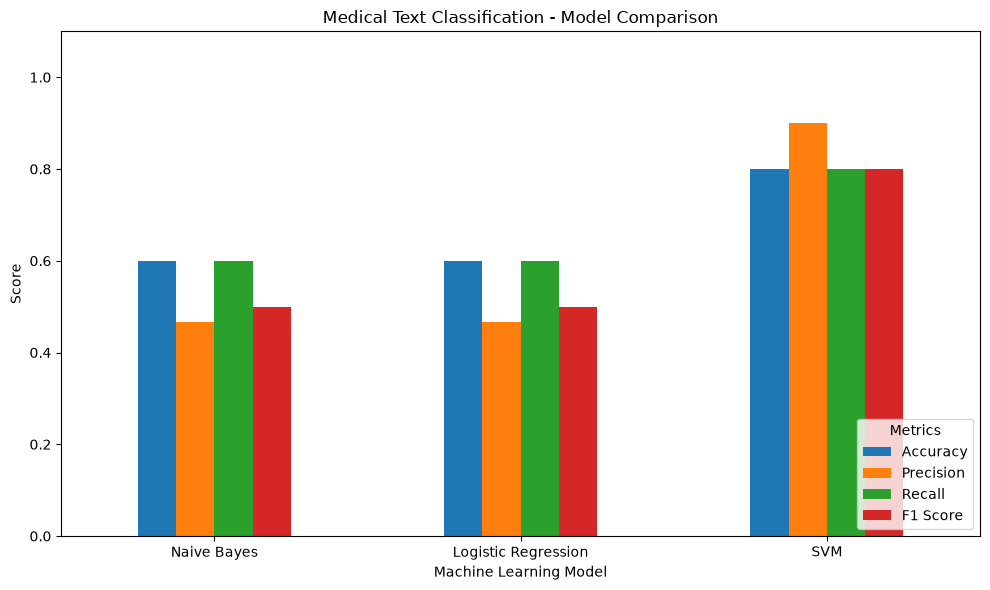


Best Model: SVM
Accuracy: 0.8
Precision: 0.9
Recall: 0.8
F1 Score: 0.8


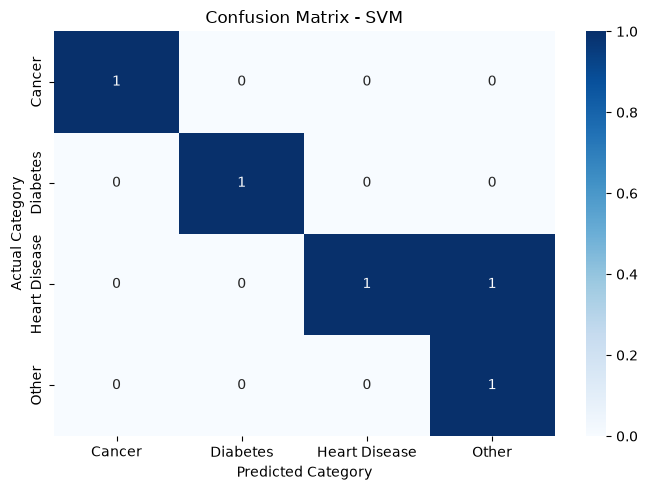


NEW MEDICAL TEXT PREDICTIONS

Medical Text:
patient has high glucose levels and excessive thirst
Predicted Category:
Diabetes

Medical Text:
patient has chest pain and difficulty breathing
Predicted Category:
Heart Disease

Medical Text:
patient has a suspicious breast lump and abnormal cells
Predicted Category:
Cancer

Medical Text:
patient has fever and cough
Predicted Category:
Other

MEDICAL TEXT CLASSIFICATION SYSTEM

Medical Text:
patient has high blood sugar

Predicted Category:
Diabetes

Experiment Completed Successfully!


In [3]:

# Experiment: Medical Text Classification using NLP

# 1. Import Libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


# 2. Create Sample Medical Text Dataset
data = {
    "text": [
        "patient has high blood sugar and frequent urination",
        "patient has increased glucose level and excessive thirst",
        "patient diagnosed with diabetes and insulin resistance",
        "blood sugar levels are elevated and patient feels very thirsty",
        "patient has diabetic symptoms and increased glucose",

        "patient has chest pain and shortness of breath",
        "patient has high blood pressure and chest discomfort",
        "patient reports irregular heartbeat and chest pain",
        "patient has cardiovascular symptoms and difficulty breathing",
        "patient has hypertension and heart problems",

        "patient has abnormal breast tissue and a suspicious lump",
        "patient diagnosed with malignant breast tumor",
        "biopsy shows abnormal cancerous cells",
        "patient has a breast mass and abnormal cells",
        "medical report indicates breast cancer",

        "patient has fever and common cold symptoms",
        "patient reports headache and mild fever",
        "patient has cough and sore throat",
        "patient has flu symptoms and body pain",
        "patient has viral infection symptoms"
    ],

    "category": [
        "Diabetes",
        "Diabetes",
        "Diabetes",
        "Diabetes",
        "Diabetes",

        "Heart Disease",
        "Heart Disease",
        "Heart Disease",
        "Heart Disease",
        "Heart Disease",

        "Cancer",
        "Cancer",
        "Cancer",
        "Cancer",
        "Cancer",

        "Other",
        "Other",
        "Other",
        "Other",
        "Other"
    ]
}

df = pd.DataFrame(data)

print("\nDataset created successfully!")
print("Dataset Shape:", df.shape)


# 3. Display Dataset Information
print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nClass Distribution:")
print(df["category"].value_counts())


# 4. Visualize Category Distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="category",
    hue="category",
    palette="viridis",
    legend=False
)

plt.title("Medical Text Category Distribution")
plt.xlabel("Medical Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


# 5. Text Preprocessing
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text


df["clean_text"] = df["text"].apply(clean_text)

print("\nOriginal and Cleaned Text:")
print(df[["text", "clean_text"]].head(10))


# 6. Separate Input and Target
X = df["clean_text"]
y = df["category"]

print("\nInput X:")
print(X.head())

print("\nTarget y:")
print(y.head())


# 7. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# 8. Create Machine Learning Models
models = {

    "Naive Bayes": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            MultinomialNB()
        )
    ]),

    "Logistic Regression": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]),

    "SVM": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LinearSVC()
        )
    ])
}

print("\nModels Created:")
for model in models:
    print("-", model)


# 9. Train and Evaluate Models
results = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

    print("\nAccuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


# 10. Compare Model Performance
results_df = pd.DataFrame(results).T

print("\nModel Performance Comparison:")
print(results_df)


# 11. Visualize Model Comparison
results_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Medical Text Classification - Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)

plt.legend(
    title="Metrics",
    loc="lower right"
)

plt.tight_layout()
plt.show()


# 12. Select Best Model
best_model_name = results_df["F1 Score"].idxmax()

best_model = models[best_model_name]

print("\nBest Model:", best_model_name)

print("Accuracy:", round(
    results_df.loc[best_model_name, "Accuracy"], 4
))

print("Precision:", round(
    results_df.loc[best_model_name, "Precision"], 4
))

print("Recall:", round(
    results_df.loc[best_model_name, "Recall"], 4
))

print("F1 Score:", round(
    results_df.loc[best_model_name, "F1 Score"], 4
))


# 13. Confusion Matrix of Best Model
y_pred_best = best_model.predict(X_test)

class_labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()


# 14. Predict New Medical Texts
new_texts = [
    "patient has high glucose levels and excessive thirst",
    "patient has chest pain and difficulty breathing",
    "patient has a suspicious breast lump and abnormal cells",
    "patient has fever and cough"
]

predictions_new = best_model.predict(new_texts)

print("\n" + "=" * 60)
print("NEW MEDICAL TEXT PREDICTIONS")
print("=" * 60)

for text, prediction in zip(new_texts, predictions_new):

    print("\nMedical Text:")
    print(text)

    print("Predicted Category:")
    print(prediction)


# 15. Predict User Input
print("\n" + "=" * 60)
print("MEDICAL TEXT CLASSIFICATION SYSTEM")
print("=" * 60)

user_text = input("\nEnter medical text: ")

# Clean user input
user_text_clean = clean_text(user_text)

# Predict category
prediction = best_model.predict([user_text_clean])

print("\nMedical Text:")
print(user_text)

print("\nPredicted Category:")
print(prediction[0])

print("\nExperiment Completed Successfully!")
